# Imprint reruns of 12 Nov 2026: DES CS A, DELVE CS A, DELVE response A

Chains from `batch_runs` (`cosmorun_DES_csimprint_A`, `cosmorun_DELVE_csimprint_A`, `cosmorun_DELVE_respimprint_A`).

* **DES CS A**: η swap fixed, colour-map holes filled (clean_sims bea6cd1, 29024fc).
* **DELVE CS A**: colour-map holes filled.
* **DELVE resp A**: catalog-mean R (clean_sims 19aa796), fiducial ξ in the two θ bins below the 3.4′ response pixel (cosmolib de080b7).

Each rerun is compared with its fiducial and with the superseded chain in `output/old_results_7/` (if that file is there).
Shifts are given as (imprint − fiducial) / σ_fiducial on the weighted posterior means.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import getdist
from getdist import plots, MCSamples
%matplotlib inline

OUT = Path.home() / 'weaklens' / 'cosmolib' / 'output'
OLD = OUT / 'old_results_7'

def chain_path(survey, tag, old=False):
    # survey: 'des-y3' or 'delve-dr3'; tag: 'fidA', 'psfA', 'respA', 'dcrA', 'csA'
    return (OLD if old else OUT) / f'shrihan-clean-{survey}-{tag}-nautilus.txt'

PARAMS = ['Om', 'sigma8', 's8', 'ns', 'Ob', 'h0']
LABELS = [r'\Omega_{\rm m}', r'\sigma_8', r'S_8', r'n_s', r'\Omega_{\rm b}', r'h']

def load(path, label):
    # Read a nautilus chain written by cosmosis; return MCSamples, or None if the file is missing.
    path = Path(path)
    if not path.exists():
        print(f'  missing: {path}')
        return None
    c = np.genfromtxt(path, names=True)
    om, s8_ = c['cosmological_parametersomega_m'], c['COSMOLOGICAL_PARAMETERSSIGMA_8']
    lw = c['log_weight']
    w = np.exp(lw - lw.max())            # subtract max so no weight underflows to 0
    samples = np.c_[om, s8_, s8_ * np.sqrt(om / 0.3),
                    c['cosmological_parametersn_s'], c['cosmological_parametersomega_b'],
                    c['cosmological_parametersh0']]
    mtime = path.stat().st_mtime
    import datetime
    print(f'  {label:28s} {len(c):7d} samples, n_eff = {w.sum()**2 / (w**2).sum():8.0f}, '
          f'written {datetime.datetime.fromtimestamp(mtime):%Y-%m-%d %H:%M}')
    return MCSamples(samples=samples, weights=w, names=PARAMS, labels=LABELS, label=label,
                     settings={'ignore_rows': 0})

In [2]:
# Load fiducial, the three rerun chains, the superseded versions, and the other imprints for context.
ch = {}
for survey, name in [('des-y3', 'DES'), ('delve-dr3', 'DELVE')]:
    print(name)
    ch[name, 'fid']  = load(chain_path(survey, 'fidA'), f'{name} fiducial')
    ch[name, 'psf']  = load(chain_path(survey, 'psfA'), f'{name} PSF imprint')
    ch[name, 'dcr']  = load(chain_path(survey, 'dcrA'), f'{name} DCR imprint')
    ch[name, 'resp'] = load(chain_path(survey, 'respA'), f'{name} resp. imprint')
    ch[name, 'cs']   = load(chain_path(survey, 'csA'), f'{name} CS imprint (new)')
    ch[name, 'cs_old'] = load(chain_path(survey, 'csA', old=True), f'{name} CS imprint (old)')
ch['DELVE', 'resp_old'] = load(chain_path('delve-dr3', 'respA', old=True), 'DELVE resp. imprint (old)')

DES


  DES fiducial                   25200 samples, n_eff =    10005, written 2026-08-27 07:14
Removed no burn in


  DES PSF imprint                32000 samples, n_eff =    10026, written 2026-08-27 11:13
Removed no burn in


  DES DCR imprint                30600 samples, n_eff =    10039, written 2026-08-27 10:54
Removed no burn in


  DES resp. imprint              25300 samples, n_eff =    10026, written 2026-08-27 10:57
Removed no burn in
  DES CS imprint (new)           26100 samples, n_eff =    10043, written 2026-11-13 09:28
Removed no burn in
  DES CS imprint (old)           23800 samples, n_eff =    10047, written 2026-08-27 10:04
Removed no burn in
DELVE
  DELVE fiducial                 19300 samples, n_eff =    10004, written 2026-09-04 00:57
Removed no burn in
  DELVE PSF imprint              18500 samples, n_eff =    10040, written 2026-09-04 00:56
Removed no burn in
  DELVE DCR imprint              21600 samples, n_eff =    10031, written 2026-09-04 01:21
Removed no burn in


  DELVE resp. imprint            21400 samples, n_eff =    10016, written 2026-11-13 09:40
Removed no burn in
  DELVE CS imprint (new)         18900 samples, n_eff =    10054, written 2026-11-13 09:12
Removed no burn in
  DELVE CS imprint (old)         20000 samples, n_eff =    10041, written 2026-09-04 01:18
Removed no burn in
  DELVE resp. imprint (old)      18000 samples, n_eff =    10032, written 2026-10-08 10:38
Removed no burn in


## Shifts relative to the fiducial chain

ΔX/σ = (mean_imprint − mean_fid) / σ_fid for each parameter. The rows marked *new* are the 12 Nov reruns. The "old" rows are the superseded chains: their DES CS had the DECADE η, and their DELVE resp A was actually a seed-C run.

In [3]:
def stats(s, p):
    return s.mean(p), s.std(p)

rows = [('DES', 'psf'), ('DES', 'resp'), ('DES', 'dcr'), ('DES', 'cs'), ('DES', 'cs_old'),
        ('DELVE', 'psf'), ('DELVE', 'resp'), ('DELVE', 'resp_old'), ('DELVE', 'dcr'), ('DELVE', 'cs'), ('DELVE', 'cs_old')]
new = {('DES', 'cs'), ('DELVE', 'cs'), ('DELVE', 'resp')}
show = ['s8', 'Om', 'sigma8']

print(f'{"chain":32s}' + ''.join(f'{p:>16s}' for p in show) + '   (shift in units of fiducial sigma)')
for survey, key in rows:
    s, f = ch.get((survey, key)), ch.get((survey, 'fid'))
    if s is None or f is None:
        continue
    out = []
    for p in show:
        mf, sf = stats(f, p)
        mi, _ = stats(s, p)
        out.append(f'{(mi - mf) / sf:+16.2f}')
    flag = '  <- new' if (survey, key) in new else ''
    print(f'{s.label:32s}' + ''.join(out) + flag)

print()
for survey in ['DES', 'DELVE']:
    f = ch.get((survey, 'fid'))
    if f is not None:
        m, sd = stats(f, 's8')
        print(f'{survey} fiducial: S8 = {m:.4f} +- {sd:.4f}')

chain                                         s8              Om          sigma8   (shift in units of fiducial sigma)
DES PSF imprint                            -0.01           -0.10           +0.08
DES resp. imprint                          +0.10           +0.04           +0.00
DES DCR imprint                            +0.02           -0.00           +0.01
DES CS imprint (new)                       -0.16           +0.04           -0.09  <- new
DES CS imprint (old)                       +0.09           +0.08           -0.04
DELVE PSF imprint                          -0.09           -0.03           -0.00
DELVE resp. imprint                        +0.12           +0.07           -0.02  <- new
DELVE resp. imprint (old)                  -0.32           +0.17           -0.23
DELVE DCR imprint                          +0.09           -0.13           +0.14
DELVE CS imprint (new)                     +0.01           +0.02           -0.01  <- new
DELVE CS imprint (old)                     +0.02

## New vs old vs fiducial, one panel per rerun

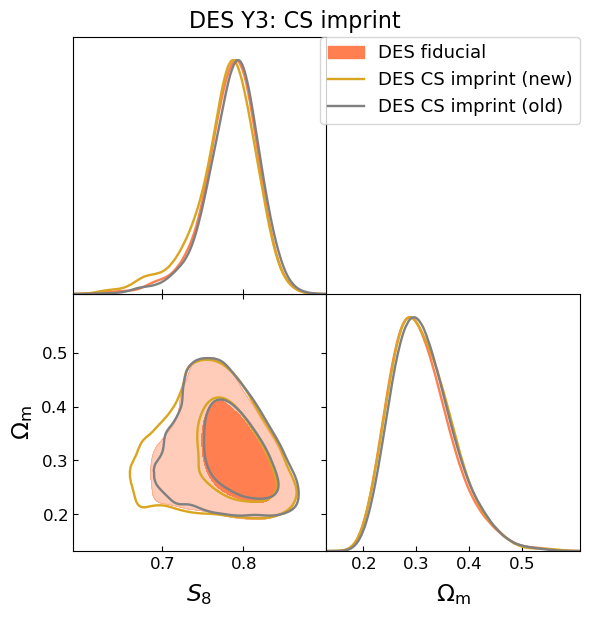

In [4]:
def tri(chains, colors, filled, params=('s8', 'Om'), title=None, save=None):
    keep = [(c, col, fl) for c, col, fl in zip(chains, colors, filled) if c is not None]
    g = plots.get_subplot_plotter(width_inch=6)
    g.settings.axes_labelsize = 18
    g.settings.axes_fontsize = 13
    g.settings.legend_fontsize = 14
    g.settings.linewidth = 2
    g.triangle_plot([k[0] for k in keep], list(params),
                    filled=[k[2] for k in keep], contour_colors=[k[1] for k in keep],
                    legend_labels=[k[0].label for k in keep], legend_loc='upper right')
    if title:
        g.fig.suptitle(title, y=1.02, fontsize=16)
    if save:
        plt.savefig(save, dpi=300, bbox_inches='tight')
    plt.show()

tri([ch['DES', 'fid'], ch['DES', 'cs'], ch['DES', 'cs_old']],
    ['coral', 'goldenrod', 'grey'], [True, False, False], title='DES Y3: CS imprint')

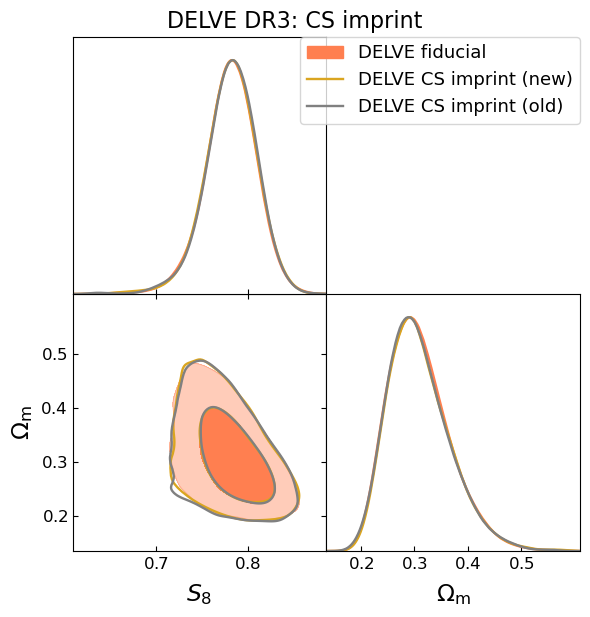

In [5]:
tri([ch['DELVE', 'fid'], ch['DELVE', 'cs'], ch['DELVE', 'cs_old']],
    ['coral', 'goldenrod', 'grey'], [True, False, False], title='DELVE DR3: CS imprint')

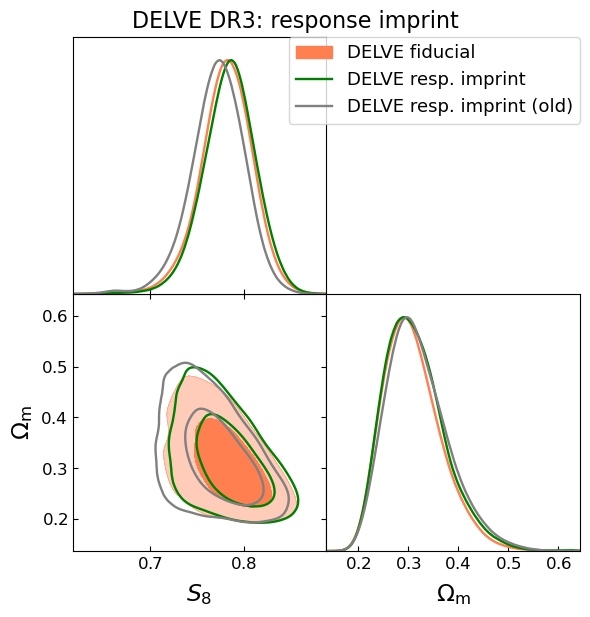

In [6]:
tri([ch['DELVE', 'fid'], ch['DELVE', 'resp'], ch['DELVE', 'resp_old']],
    ['coral', 'green', 'grey'], [True, False, False], title='DELVE DR3: response imprint')

## All imprints per survey (current chains)

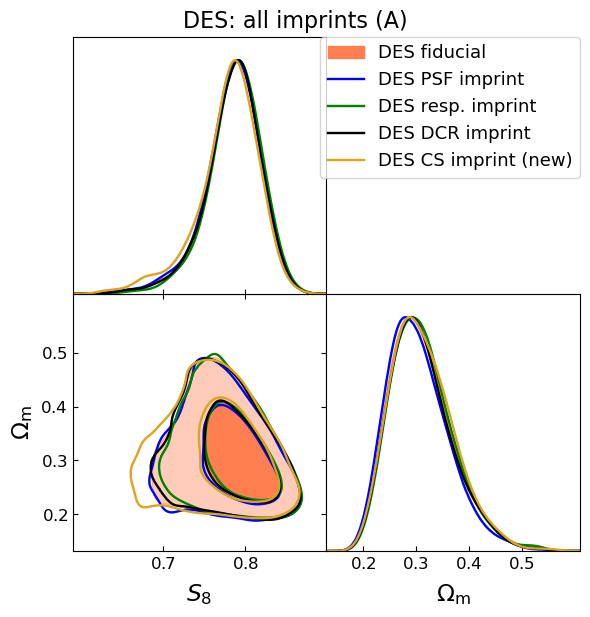

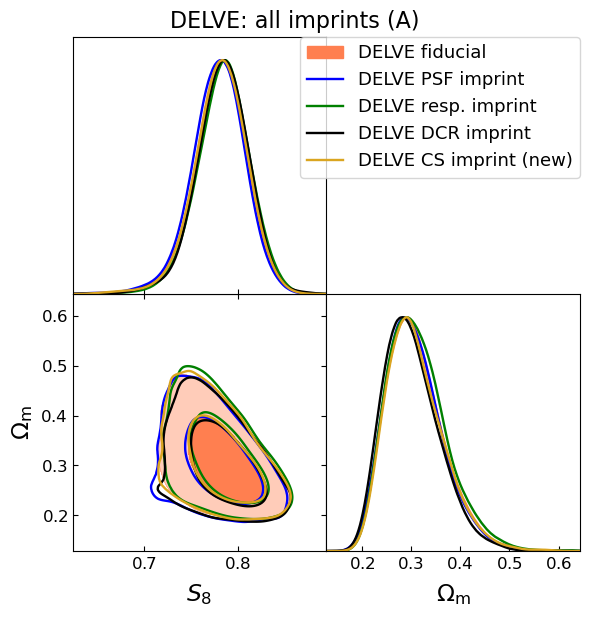

In [7]:
for survey in ['DES', 'DELVE']:
    tri([ch[survey, k] for k in ['fid', 'psf', 'resp', 'dcr', 'cs']],
        ['coral', 'blue', 'green', 'black', 'goldenrod'], [True, False, False, False, False],
        title=f'{survey}: all imprints (A)')

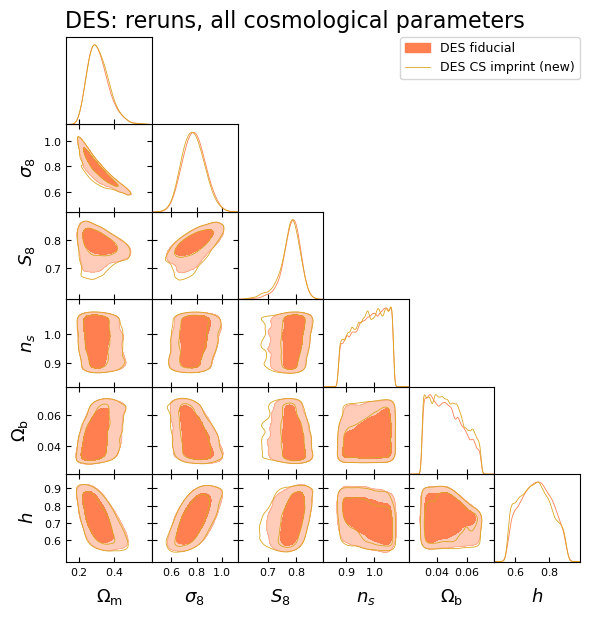

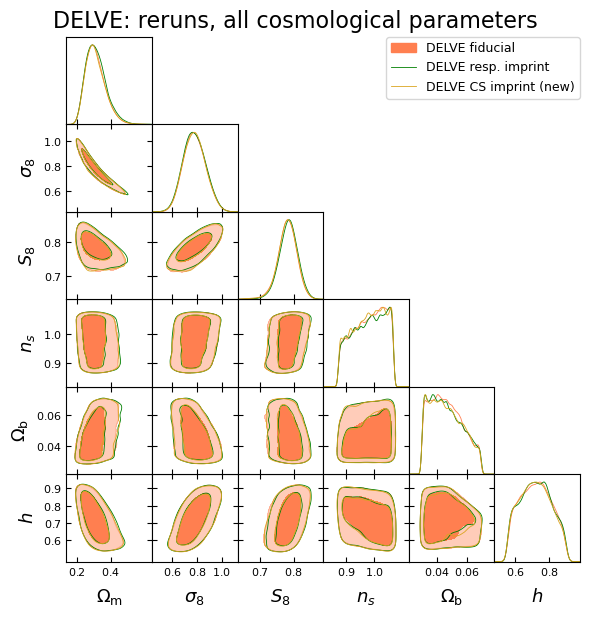

In [8]:
# Full cosmology triangle for the three reruns against fiducial (check nothing odd in ns, Ob, h).
for survey, keys in [('DES', ['fid', 'cs']), ('DELVE', ['fid', 'resp', 'cs'])]:
    cols = {'fid': 'coral', 'resp': 'green', 'cs': 'goldenrod'}
    tri([ch[survey, k] for k in keys], [cols[k] for k in keys], [True] + [False] * (len(keys) - 1),
        params=PARAMS, title=f'{survey}: reruns, all cosmological parameters')